In [1]:
import pandas as pd
import re
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.metrics.pairwise import cosine_distances
import nltk
import time
import sys
import os
import matplotlib.pyplot as plt

In [2]:
stop_words = {'a', "a's", 'able', 'about', 'above', 'according', 'accordingly', 'across', 'actually', 'after', 'afterwards', 'again', 'against', "ain't", 'all', 'allow', 'allows', 'almost', 'alone', 'along', 'already', 'also', 'although', 'always', 'am', 'among', 'amongst', 'an', 'and', 'another', 'any', 'anybody', 'anyhow', 'anyone', 'anything', 'anyway', 'anyways', 'anywhere', 'apart', 'appear', 'appreciate', 'appropriate', 'are', "aren't", 'around', 'as', 'aside', 'ask', 'asking', 'associated', 'at', 'available', 'away', 'awfully', 'b', 'be', 'became', 'because', 'become', 'becomes', 'becoming', 'been', 'before', 'beforehand', 'behind', 'being', 'believe', 'below', 'beside', 'besides', 'best', 'better', 'between', 'beyond', 'both', 'brief', 'but', 'by', 'c', "c'mon", "c's", 'came', 'can', "can't", 'cannot', 'cant', 'cause', 'causes', 'certain', 'certainly', 'changes', 'clearly', 'co', 'com', 'come', 'comes', 'concerning', 'consequently', 'consider', 'considering', 'contain', 'containing', 'contains', 'corresponding', 'could', "couldn't", 'course', 'currently', 'd', 'definitely', 'described', 'despite', 'did', "didn't", 'different', 'do', 'does', "doesn't", 'doing', "don't", 'done', 'down', 'downwards', 'during', 'e', 'each', 'edu', 'eg', 'eight', 'either', 'else', 'elsewhere', 'enough', 'entirely', 'especially', 'et', 'etc', 'even', 'ever', 'every', 'everybody', 'everyone', 'everything', 'everywhere', 'ex', 'exactly', 'example', 'except', 'f', 'far', 'few', 'fifth', 'first', 'five', 'followed', 'following', 'follows', 'for', 'former', 'formerly', 'forth', 'four', 'from', 'further', 'furthermore', 'g', 'get', 'gets', 'getting', 'given', 'gives', 'go', 'goes', 'going', 'gone', 'got', 'gotten', 'greetings', 'h', 'had', "hadn't", 'happens', 'hardly', 'has', "hasn't", 'have', "haven't", 'having', 'he', "he's", 'hello', 'help', 'hence', 'her', 'here', "here's", 'hereafter', 'hereby', 'herein', 'hereupon', 'hers', 'herself', 'hi', 'him', 'himself', 'his', 'hither', 'hopefully', 'how', 'howbeit', 'however', 'i', "i'd", "i'll", "i'm", "i've", 'ie', 'if', 'ignored', 'immediate', 'in', 'inasmuch', 'inc', 'indeed', 'indicate', 'indicated', 'indicates', 'inner', 'insofar', 'instead', 'into', 'inward', 'is', "isn't", 'it', "it'd", "it'll", "it's", 'its', 'itself', 'j', 'just', 'k', 'keep', 'keeps', 'kept', 'know', 'known', 'knows', 'l', 'last', 'lately', 'later', 'latter', 'latterly', 'least', 'less', 'lest', 'let', "let's", 'like', 'liked', 'likely', 'little', 'look', 'looking', 'looks', 'ltd', 'm', 'mainly', 'many', 'may', 'maybe', 'me', 'mean', 'meanwhile', 'merely', 'might', 'more', 'moreover', 'most', 'mostly', 'much', 'must', 'my', 'myself', 'n', 'name', 'namely', 'nd', 'near', 'nearly', 'necessary', 'need', 'needs', 'neither', 'never', 'nevertheless', 'new', 'next', 'nine', 'no', 'nobody', 'non', 'none', 'noone', 'nor', 'normally', 'not', 'nothing', 'novel', 'now', 'nowhere', 'o', 'obviously', 'of', 'off', 'often', 'oh', 'ok', 'okay', 'old', 'on', 'once', 'one', 'ones', 'only', 'onto', 'or', 'other', 'others', 'otherwise', 'ought', 'our', 'ours', 'ourselves', 'out', 'outside', 'over', 'overall', 'own', 'p', 'particular', 'particularly', 'per', 'perhaps', 'placed', 'please', 'plus', 'possible', 'presumably', 'probably', 'provides', 'q', 'que', 'quite', 'qv', 'r', 'rather', 'rd', 're', 'really', 'reasonably', 'regarding', 'regardless', 'regards', 'relatively', 'respectively', 'right', 's', 'said', 'same', 'saw', 'say', 'saying', 'says', 'second', 'secondly', 'see', 'seeing', 'seem', 'seemed', 'seeming', 'seems', 'seen', 'self', 'selves', 'sensible', 'sent', 'serious', 'seriously', 'seven', 'several', 'shall', 'she', 'should', "shouldn't", 'since', 'six', 'so', 'some', 'somebody', 'somehow', 'someone', 'something', 'sometime', 'sometimes', 'somewhat', 'somewhere', 'soon', 'sorry', 'specified', 'specify', 'specifying', 'still', 'sub', 'such', 'sup', 'sure', 't', "t's", 'take', 'taken', 'tell', 'tends', 'th', 'than', 'thank', 'thanks', 'thanx', 'that', "that's", 'thats', 'the', 'their', 'theirs', 'them', 'themselves', 'then', 'thence', 'there', "there's", 'thereafter', 'thereby', 'therefore', 'therein', 'theres', 'thereupon', 'these', 'they', "they'd", "they'll", "they're", "they've", 'think', 'third', 'this', 'thorough', 'thoroughly', 'those', 'though', 'three', 'through', 'throughout', 'thru', 'thus', 'to', 'together', 'too', 'took', 'toward', 'towards', 'tried', 'tries', 'truly', 'try', 'trying', 'twice', 'two', 'u', 'un', 'under', 'unfortunately', 'unless', 'unlikely', 'until', 'unto', 'up', 'upon', 'us', 'use', 'used', 'useful', 'uses', 'using', 'usually', 'uucp', 'v', 'value', 'various', 'very', 'via', 'viz', 'vs', 'w', 'want', 'wants', 'was', "wasn't", 'way', 'we', "we'd", "we'll", "we're", "we've", 'welcome', 'well', 'went', 'were', "weren't", 'what', "what's", 'whatever', 'when', 'whence', 'whenever', 'where', "where's", 'whereafter', 'whereas', 'whereby', 'wherein', 'whereupon', 'wherever', 'whether', 'which', 'while', 'whither', 'who', "who's", 'whoever', 'whole', 'whom', 'whose', 'why', 'will', 'willing', 'wish', 'with', 'within', 'without', "won't", 'wonder', 'would', "wouldn't", 'x', 'y', 'yes', 'yet', 'you', "you'd", "you'll", "you're", "you've", 'your', 'yours', 'yourself', 'yourselves', 'z', 'zero'}

data = pd.read_csv("data/features-annotated-artistless-with-lyrics-and-languages.csv")
# remove songs with missing lyrics and reset the index
data = data.dropna(subset=['lyrics']).reset_index(drop=True)
data

,id,Rank,Title,Primary Artists,Featuring Artists,Date,Danceability,Energy,Loudness,Speechiness,Acousticness,Instrumentalness,Valence,Nationality,Continent,Points (Total),lyrics,detected_languages,num_languages,language_confidences
0,47EiUVwUp4C9fGccaPuUCS,1,dákiti,"bad bunny, jhayco",NaN,26/11/2020,0.731,0.573,-10059.00,0.054,0.401,0.000,0.145,puerto rico,latin-america,200,"Baby, ya yo me enteré, se nota cuando me ve'\n...",SPANISH,1,SPANISH: 1.0
1,7igeByaBM0MgGsgXtNxDJ7,1,positions,ariana grande,NaN,29/10/2020,0.736,0.802,-4759.00,0.086,0.468,0.000,0.675,united states,anglo-america,200,Heaven sent you to me\nI'm just hopin’ I don't...,ENGLISH,1,ENGLISH: 1.0
2,3qQbCzHBycnDpGskqOWY0E,1,ella baila sola,"eslabon armado, peso pluma",NaN,29/05/2023,0.668,0.758,-5176.00,0.033,0.483,0.000,0.834,mexico,latin-america,200,"Compa, ¿qué le parece esa morra?\nLa que anda ...",SPANISH,1,SPANISH: 1.0
3,0Yde1VrWbGF2Tus2AQhMuT,1,circles,post malone,NaN,06/09/2019,0.703,0.756,-3407.00,0.038,0.222,0.003,0.536,united states,anglo-america,200,"Oh, oh, oh\nOh, oh, oh\nOh, oh, oh, oh, oh\n...",ENGLISH,1,ENGLISH: 1.0
4,0TK2YIli7K1leLovkQiNik,1,señorita,"camila cabello, shawn mendes",NaN,25/07/2019,0.759,0.540,-6039.00,0.029,0.037,0.000,0.750,canada,anglo-america,200,I love it when you call me señorita\nI wish I ...,ENGLISH,1,ENGLISH: 1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8029,7wBJfHzpfI3032CSD7CE2m,200,stargazing,travis scott,NaN,14/05/2020,0.487,0.789,-3.69,0.044,0.009,0.000,0.056,united states,anglo-america,1,"Ah\n\nRollin', rollin', rollin', got me starga...",ENGLISH,1,ENGLISH: 1.0
8030,7yotKA30dwTKNEGomV9ZsI,200,kod,j. cole,NaN,28/06/2018,0.823,0.783,-6274.00,0.154,0.210,0.000,0.199,united states,anglo-america,1,"Go, go, go\nGo, go, go\nGo, go, go\nGo, go, go...",ENGLISH,1,ENGLISH: 1.0
8031,5FOCkGt7bp22nBVfQ4WSIT,200,indecente,anitta,NaN,19/04/2018,0.874,0.602,-5118.00,0.127,0.160,0.001,0.587,brazil,latin-america,1,"Una mirada te delata, un perfume que te atrapa...",SPANISH,1,SPANISH: 1.0
8032,7zQirOExB0VR8yWUOqYeio,200,dolla sign slime (feat. megan thee stallion),lil nas x,megan thee stallion,27/09/2021,0.923,0.533,-6016.00,0.262,0.050,0.000,0.587,united states,anglo-america,1,Day-Day-Daytrip took it to ten (\nHey\n)\n\nY'...,ENGLISH,1,ENGLISH: 1.0


In [3]:
# Map a function to a list and then flatten it (if it's a list of lists it becomes a list)
def flatmap(func: callable, lst: list) -> list:
    return [item for sublist in map(func, lst) for item in sublist]

# Update a dictionary of lists, creating an empty list if one doesn't exists
def update_dict_list(d: dict, key, value):
    if key not in d:
        d[key] = []
    if value not in d[key]:
        d[key].append(value)

# Process a term and produce a potentially unary list of processed terms
def process_term(t: str) -> list[str]:
    # Force to lower case
    t = t.lower()
    
    # Remove leading and trailing non-alphanumeric characters
    while t and not t[0].isalnum():
        t = t[1:]
    while t and not t[-1].isalnum():
        t = t[:-1]    

    # Split on dashes, which may produce multiple terms (hence the list return)
    t = t.split("-")

    # Remove stopwords, set is used for O(1) lookup
    t = filter(lambda term: term not in stop_words, t)

    # Stem using the NLTK porter stemmer
    # Use Snowball stemmer. Language is unknown so default to English as a reasonable fallback.
    stemmer = nltk.SnowballStemmer("english")
    t = map(lambda term: stemmer.stem(term), t)

    return list(t)

# Get the document numbers for a given term (or negated term) from the postings
def get_term_docnos(term: str, negated: bool) -> set[int]:
    # If term is empty or doesn't appear in the postings list return an empty set
    if not term or term not in postings:
        return set()
    
    # Get the set of ids for all documents containing the term
    doc_set = {docid for docid, _ in postings[term]}

    # If we want the negated term, find all documents not in doc_set via set difference
    if negated:
        # all_docnos is computed once globally to reduce recomputation
        return all_docnos - doc_set
    # ... otherwise return the doc_set
    return doc_set

def format_seconds(sec: float) -> str:
        sec = int(sec)
        m, s = divmod(sec, 60)
        h, m = divmod(m, 60)
        if h:
            return f"{h}h{m:02d}m{s:02d}s"
        if m:
            return f"{m}m{s:02d}s"
        return f"{s}s"

In [4]:
postings = {}
idx_to_id = {}
num_songs = data.shape[0]
postings_start_time = time.time()

filepath = "data/postings.txt"

# If the postings have been processed previously, read them in
if os.path.exists(filepath):
    # Read postings from the file written by the later cell
    current_term = None
    with open(filepath, 'r', encoding='utf-8') as f:
        for line in f:
            if not line.strip():
                continue
            # Header lines: term:df
            if not line.startswith('\t'):
                term, _ = line.strip().split(':', 1)
                current_term = term
                postings[current_term] = []
            else:
                # Entry lines: \t{docid}: {pos1,pos2,...}
                entry = line.strip()
                docid_str, positions_str = entry.split(':', 1)
                docid = int(docid_str.strip())
                positions = [p.strip() for p in positions_str.split(',') if p.strip() != ""]
                for p in positions:
                    postings[current_term].append((docid, int(p)))
    # Populate idx_to_id from the dataframe (docids in postings correspond to row indices)
    for idx, row in data.iterrows():
        idx_to_id[idx] = row["id"]

# If the postings haven't been processed we need to process them and write to the file
else:
    for song_idx, row in data.iterrows():
        # Progress bar for large datasets (use song_idx to avoid needing pos_in_file)
        pos_in_file = song_idx + 1
        progress = min(1.0, pos_in_file / num_songs) if num_songs > 0 else 0
        bar_length = 40
        filled_length = int(bar_length * progress)
        bar = '=' * filled_length + '-' * (bar_length - filled_length)
        elapsed = time.time() - postings_start_time
        
        print(f"\rProgress: [{bar}] ({pos_in_file}/{num_songs}) {int(progress * 100)}% | Elapsed: {format_seconds(elapsed)}", end='')
        sys.stdout.flush()

        idx_to_id[song_idx] = row["id"] 
        lyrics = row["lyrics"].strip()

        # Normalize quotes/newlines and remove unwanted punctuation while preserving apostrophes and hyphens
        lyrics = lyrics.replace('\r', ' ')
        lyrics = lyrics.replace('\u2018', "'").replace('\u2019', "'").replace('\u201c', '"').replace('\u201d', '"')
        lyrics = re.sub(r'[\n\t]+', ' ', lyrics)
        lyrics = re.sub(r"[^\w'\- ]+", ' ', lyrics, flags=re.UNICODE)
        lyrics = re.sub(r'\s+', ' ', lyrics).strip()

        # Skip empty lyrics after normalization
        if not lyrics:
            continue

        # Split the data and process each term. process_term returns a list so we flatten the map
        line = flatmap(process_term, lyrics.split(" "))

        # Remove the empty string
        line = filter(lambda t: t != "", line)

        for pos, term in enumerate(line):
            update_dict_list(postings, term, (song_idx, pos))

    # Sort postings by the length of their posting lists (most frequent terms first)
    postings = dict(sorted(postings.items(), key=lambda item: len(item[1]), reverse=True))
    filepath = "data/postings.txt"

    # Write to file
    os.makedirs(os.path.dirname(filepath), exist_ok=True)
    with open(filepath, 'w') as f:
        for term in postings.keys():
            # Postings are stored as (docid, pos) pairs, so retrieve all pos for each document
            doc_positions = {}
            for docid, pos in postings[term]:
                # Need to convert pos to string for later concatenation
                update_dict_list(doc_positions, docid, str(pos))

            # Write the results to the file, starting with the header
            df = len(doc_positions)
            f.write(f"{term}:{df}\n")
            # ... then each entry
            for docid in sorted(doc_positions.keys()):
                positions = ",".join(sorted(doc_positions[docid]))
                f.write(f"\t{docid}: {positions}\n")

# all_docnos used by get_term_docnos: set of all document indices
all_docnos = set(range(num_songs))

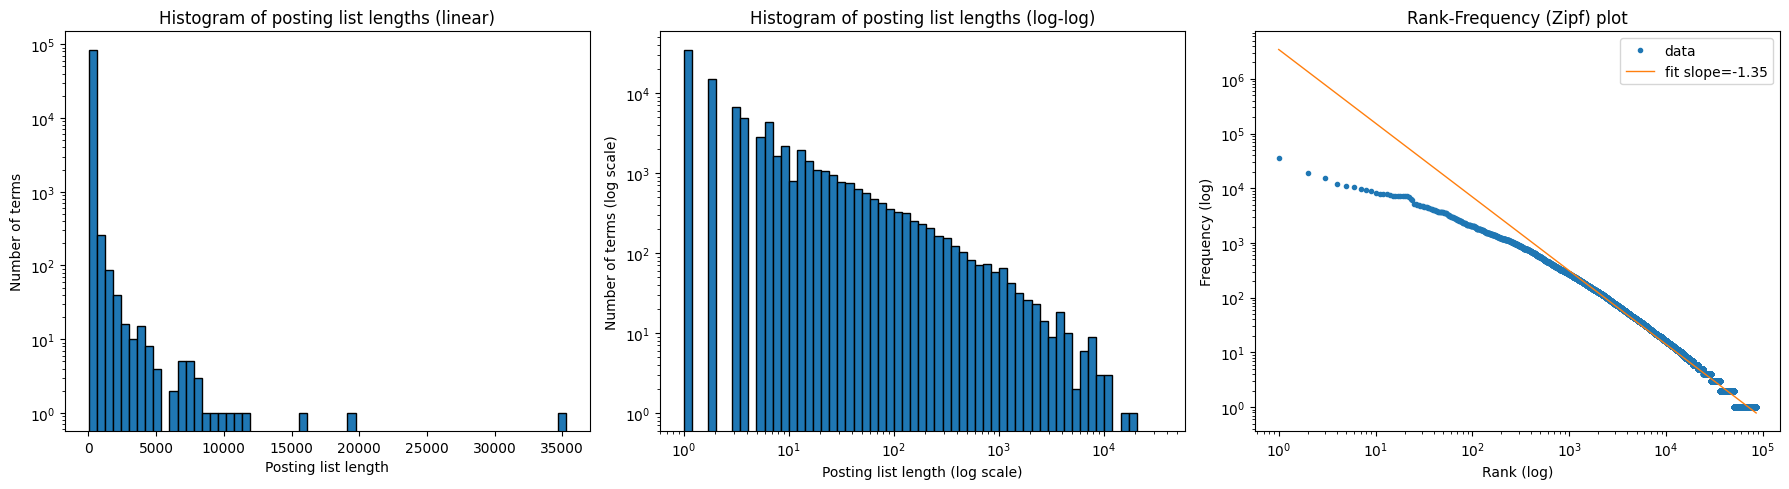

In [ ]:
# compute posting-list lengths
freqs = np.array([len(lst) for lst in postings.values()])
freqs = freqs[freqs > 0]
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Linear x, log y histogram
bins_lin = np.linspace(1, freqs.max(), 60)
axes[0].hist(freqs, bins=bins_lin, color='C0', edgecolor='black')
axes[0].set_yscale('log')
axes[0].set_xlabel('Posting list length')
axes[0].set_ylabel('Number of terms (log scale)')
axes[0].set_title('Histogram of posting list lengths (linear)')

# Histogram with logarithmic bins and log-log axes to visualise long tail
bins_log = np.logspace(np.log10(1), np.log10(freqs.max()), 60)
axes[1].hist(freqs, bins=bins_log, color='C0', edgecolor='black')
axes[1].set_xscale('log')
axes[1].set_yscale('log')
axes[1].set_xlabel('Posting list length (log scale)')
axes[1].set_ylabel('Number of terms (log scale)')
axes[1].set_title('Histogram of posting list lengths (log-log)')

# Rank-frequency Zipf plot (log-log)
freq_sorted = np.sort(freqs)[::-1]
ranks = np.arange(1, len(freq_sorted) + 1)
axes[2].loglog(ranks, freq_sorted, marker='.', linestyle='none', label='data')

# Fit a power-law (linear fit in log-log) and plot the fitted curve
coef = np.polyfit(np.log(ranks), np.log(freq_sorted), 1)
slope, intercept = coef[0], coef[1]
fit = np.exp(intercept) * ranks ** slope
axes[2].loglog(ranks, fit, color='C1', lw=1, label=f'fit slope={slope:.2f}')

axes[2].set_xlabel('Rank (log)')
axes[2].set_ylabel('Frequency (log)')
axes[2].set_title('Rank-Frequency (Zipf) plot')
axes[2].legend()

plt.tight_layout()
plt.show()